# Kasus Diskusi 6 
**STIK4121 – Metode Statistik**

Apakah terdapat perbedaan rata-rata nilai kuis mahasiswa berdasarkan metode belajar utama
(membaca BMP/modul, menonton video pembelajaran, mengerjakan latihan soal)?

- **Variabel respons:** nilai kuis
- **Faktor:** metode belajar utama (3 kelompok)
- **Taraf nyata:** α = 0,05

## 1. TABLE DATA

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

alpha = 0.05

df = pd.DataFrame({
    "metode": ["Membaca BMP/modul"] * 5
            + ["Menonton video pembelajaran"] * 5
            + ["Mengerjakan latihan soal"] * 5,
    "nilai": [68, 70, 72, 74, 76,
              72, 74, 75, 77, 78,
              78, 80, 82, 84, 86],
})
urutan = ["Membaca BMP/modul", "Menonton video pembelajaran", "Mengerjakan latihan soal"]
df.index = df.index + 1
df

,metode,nilai
1,Membaca BMP/modul,68
2,Membaca BMP/modul,70
3,Membaca BMP/modul,72
4,Membaca BMP/modul,74
5,Membaca BMP/modul,76
6,Menonton video pembelajaran,72
7,Menonton video pembelajaran,74
8,Menonton video pembelajaran,75
9,Menonton video pembelajaran,77
10,Menonton video pembelajaran,78


## 2. Statistik deskriptif per kelompok

In [2]:
desk = (df.groupby("metode")["nilai"]
          .agg(n="count", jumlah="sum", rata_rata="mean", simpangan_baku="std")
          .reindex(urutan))
desk.loc["Total"] = [df["nilai"].count(), df["nilai"].sum(),
                     df["nilai"].mean(), df["nilai"].std()]
desk.round(2)

,n,jumlah,rata_rata,simpangan_baku
metode,,,,
Membaca BMP/modul,5.0,360.0,72.0,3.16
Menonton video pembelajaran,5.0,376.0,75.2,2.39
Mengerjakan latihan soal,5.0,410.0,82.0,3.16
Total,15.0,1146.0,76.4,5.10


In [3]:
tertinggi = desk.drop("Total")["rata_rata"].idxmax()
print(f"Rata-rata tertinggi: {tertinggi} ({desk.loc[tertinggi, 'rata_rata']:.1f})")

Rata-rata tertinggi: Mengerjakan latihan soal (82.0)


### Visualisasi sebaran nilai per kelompok
Boxplot dengan titik data asli; tanda ◆ merah adalah rata-rata kelompok.

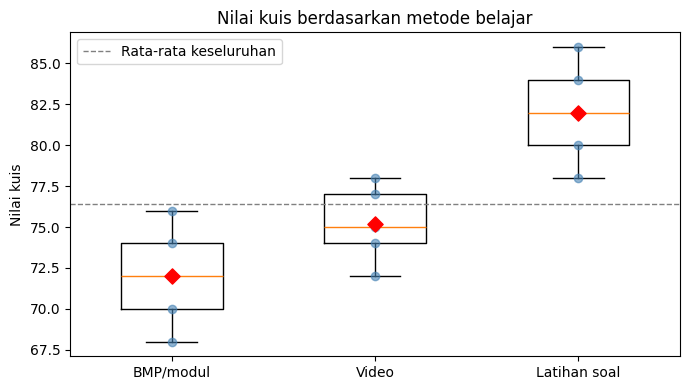

In [4]:
data_kelompok = [df.loc[df["metode"] == g, "nilai"].values for g in urutan]
label = ["BMP/modul", "Video", "Latihan soal"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(data_kelompok, tick_labels=label, widths=0.5)
for i, d in enumerate(data_kelompok, start=1):
    ax.scatter(np.full(len(d), i), d, alpha=0.6, color="steelblue", zorder=3)
    ax.scatter(i, d.mean(), marker="D", color="red", s=60, zorder=4)
ax.axhline(df["nilai"].mean(), ls="--", color="gray", lw=1, label="Rata-rata keseluruhan")
ax.set_ylabel("Nilai kuis")
ax.set_title("Nilai kuis berdasarkan metode belajar")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Hipotesis
- **H₀:** μ₁ = μ₂ = μ₃ (rata-rata nilai kuis ketiga metode sama)
- **H₁:** minimal ada satu μᵢ yang berbeda

## 4. Perhitungan ANOVA secara manual

$$JKA = \sum n_i(\bar{x}_i - \bar{x})^2 \qquad JKD = \sum\sum (x_{ij} - \bar{x}_i)^2 \qquad JKT = JKA + JKD$$

$$KT = \frac{JK}{db} \qquad F = \frac{KTA}{KTD}$$

In [5]:
k = df["metode"].nunique()          # jumlah kelompok
N = len(df)                         # jumlah observasi
grand_mean = df["nilai"].mean()

g = df.groupby("metode")["nilai"]
n_i = g.count()
mean_i = g.mean()

JKA = (n_i * (mean_i - grand_mean) ** 2).sum()
JKD = ((df["nilai"] - df["metode"].map(mean_i)) ** 2).sum()
JKT = ((df["nilai"] - grand_mean) ** 2).sum()

db_a, db_d, db_t = k - 1, N - k, N - 1
KTA, KTD = JKA / db_a, JKD / db_d
F_hitung = KTA / KTD
F_tabel = stats.f.ppf(1 - alpha, db_a, db_d)
p_value = stats.f.sf(F_hitung, db_a, db_d)

print(f"k = {k}, N = {N}, rata-rata keseluruhan = {grand_mean:.2f}")
print(f"JKA = {JKA:.2f}, JKD = {JKD:.2f}, JKT = {JKT:.2f}  (cek JKA+JKD = {JKA + JKD:.2f})")

k = 3, N = 15, rata-rata keseluruhan = 76.40
JKA = 260.80, JKD = 102.80, JKT = 363.60  (cek JKA+JKD = 363.60)


### Tabel ANOVA

In [6]:
anova = pd.DataFrame({
    "JK": [JKA, JKD, JKT],
    "db": [db_a, db_d, db_t],
    "KT": [KTA, KTD, np.nan],
    "F hitung": [F_hitung, np.nan, np.nan],
    "F tabel": [F_tabel, np.nan, np.nan],
    "p-value": [p_value, np.nan, np.nan],
}, index=["Antar kelompok", "Dalam kelompok (galat)", "Total"])
anova.round(4).fillna("")

,JK,db,KT,F hitung,F tabel,p-value
Antar kelompok,260.8,2,130.4,15.2218,3.8853,0.0005
Dalam kelompok (galat),102.8,12,8.5667,,,
Total,363.6,14,,,,


### Verifikasi dengan `scipy.stats.f_oneway`

In [7]:
hasil = stats.f_oneway(*data_kelompok)
print(f"F = {hasil.statistic:.4f}, p-value = {hasil.pvalue:.6f}")

F = 15.2218, p-value = 0.000511


### Keputusan dan kesimpulan

In [8]:
if F_hitung > F_tabel:
    print(f"F hitung ({F_hitung:.2f}) > F tabel ({F_tabel:.2f}), p-value = {p_value:.4f} < {alpha}")
    print("Keputusan : Tolak H0")
    print("Kesimpulan: Terdapat perbedaan rata-rata nilai kuis yang signifikan antar metode belajar.")
else:
    print(f"F hitung ({F_hitung:.2f}) <= F tabel ({F_tabel:.2f}), p-value = {p_value:.4f}")
    print("Keputusan : Gagal tolak H0")
    print("Kesimpulan: Tidak terdapat perbedaan rata-rata yang signifikan antar metode belajar.")

F hitung (15.22) > F tabel (3.89), p-value = 0.0005 < 0.05
Keputusan : Tolak H0
Kesimpulan: Terdapat perbedaan rata-rata nilai kuis yang signifikan antar metode belajar.


## 5. Uji lanjut (post hoc) Tukey HSD
ANOVA hanya menyatakan *minimal ada satu* rata-rata yang berbeda. Untuk mengetahui pasangan mana yang berbeda, digunakan uji Tukey HSD.

$$HSD = q_{\alpha;\,k;\,db_{galat}} \times \sqrt{\frac{KTD}{n}}$$

In [9]:
n = n_i.iloc[0]  # ukuran tiap kelompok sama (n = 5)
q_tabel = stats.studentized_range.ppf(1 - alpha, k, db_d)
HSD = q_tabel * np.sqrt(KTD / n)
print(f"q tabel (α={alpha}, k={k}, db={db_d}) = {q_tabel:.3f}")
print(f"HSD = {q_tabel:.3f} × √({KTD:.3f}/{n}) = {HSD:.3f}")

pasangan = [("Mengerjakan latihan soal", "Membaca BMP/modul"),
            ("Mengerjakan latihan soal", "Menonton video pembelajaran"),
            ("Menonton video pembelajaran", "Membaca BMP/modul")]
tukey = pd.DataFrame([{
    "Pasangan": f"{a} vs {b}",
    "Selisih": abs(mean_i[a] - mean_i[b]),
    "HSD": HSD,
    "Hasil": "Berbeda signifikan" if abs(mean_i[a] - mean_i[b]) > HSD else "Tidak berbeda signifikan",
} for a, b in pasangan])
tukey.round(2)

q tabel (α=0.05, k=3, db=12) = 3.773
HSD = 3.773 × √(8.567/5) = 4.939


,Pasangan,Selisih,HSD,Hasil
0,Mengerjakan latihan soal vs Membaca BMP/modul,10.0,4.94,Berbeda signifikan
1,Mengerjakan latihan soal vs Menonton video pem...,6.8,4.94,Berbeda signifikan
2,Menonton video pembelajaran vs Membaca BMP/modul,3.2,4.94,Tidak berbeda signifikan


### Verifikasi dengan `scipy.stats.tukey_hsd`

In [10]:
res = stats.tukey_hsd(*data_kelompok)
print("Urutan kelompok: 0 = BMP/modul, 1 = Video, 2 = Latihan soal")
print(res)

Urutan kelompok: 0 = BMP/modul, 1 = Video, 2 = Latihan soal
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -3.200     0.235    -8.139     1.739
 (0 - 2)    -10.000     0.000   -14.939    -5.061
 (1 - 0)      3.200     0.235    -1.739     8.139
 (1 - 2)     -6.800     0.008   -11.739    -1.861
 (2 - 0)     10.000     0.000     5.061    14.939
 (2 - 1)      6.800     0.008     1.861    11.739



## 6. Ringkasan
| Hasil | Nilai |
|---|---|
| Rata-rata BMP / Video / Latihan | 72,0 / 75,2 / 82,0 |
| F hitung vs F tabel | 15,22 > 3,89 |
| p-value | ≈ 0,0005 |
| Keputusan | Tolak H₀ |
| Tukey | Latihan soal berbeda nyata dengan BMP dan video; BMP vs video tidak berbeda nyata |

**Implikasi bagi tutor:** perbanyak latihan soal dalam tuton dan kombinasikan dengan modul serta video.
Karena data bersifat observasional dan sampel kecil (5 per kelompok), hasil ini belum membuktikan hubungan sebab-akibat.

## 7. Jawaban Pertanyaan

**1.** Variabel respons: **nilai kuis mahasiswa**.

**2.** Faktor: **metode belajar utama**.

**3.** Ada **3 kelompok**: membaca BMP/modul, menonton video pembelajaran, dan mengerjakan latihan soal.

**4.** Ada satu variabel respons kuantitatif dan satu faktor dengan lebih dari dua kelompok yang saling bebas. Tujuannya membandingkan rata-rata ketiga kelompok sekaligus.

**5.** Uji-t berulang (3 kali) memperbesar peluang kesalahan tipe I menjadi 1 − (0,95)³ ≈ 14,3%, bukan 5%. ANOVA menguji semuanya sekaligus dengan α tetap 0,05.

**6.** H₀: μ₁ = μ₂ = μ₃; H₁: minimal ada satu μᵢ yang berbeda.

**7.** **Mengerjakan latihan soal** (rata-rata 82,0), diikuti video (75,2) dan BMP (72,0).

**8.**

| Sumber | JK | db | KT | F hitung | F tabel |
|---|---|---|---|---|---|
| Antar kelompok | 260,8 | 2 | 130,40 | 15,22 | 3,89 |
| Galat | 102,8 | 12 | 8,57 | | |
| Total | 363,6 | 14 | | | |

F hitung (15,22) > F tabel (3,89) dan p-value ≈ 0,0005 < 0,05, maka **H₀ ditolak**. Terdapat perbedaan rata-rata nilai kuis yang signifikan antar metode belajar.

**9.** **Tidak.** ANOVA hanya menunjukkan bahwa minimal ada satu rata-rata yang berbeda. Pasangan yang berbeda harus dicari dengan uji lanjut, misalnya Tukey HSD (HSD = 4,94). Hasilnya: latihan soal berbeda nyata dengan BMP (selisih 10,0) dan dengan video (selisih 6,8), sedangkan BMP vs video tidak berbeda nyata (selisih 3,2).

**10.** Tutor dapat memperbanyak latihan soal dalam tuton dan memakai BMP serta video sebagai dasar konsep yang ditutup dengan latihan soal.